# Barrido del tamaño de ventana con GRU, NSL-KDD

Entrena el autoencoder GRU con distintos tamaños de ventana W y registra el número de ventanas de entrenamiento, la memoria que ocupan, el tiempo de entrenamiento y el AUC. Se entrena con KDDTrain+_20Percent y se evalúa con KDDTest+, que incluye tipos de ataque no vistos en entrenamiento.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

In [2]:
COL_NAMES = [
    'duration', 'protocol_type', 'service', 'flag',
    'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
    'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
    'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty'
]
BASE = Path.home() / ".cache/kagglehub/datasets/hassan06/nslkdd/versions/1"
df_train = pd.read_csv(BASE / "KDDTrain+_20Percent.txt", header=None, names=COL_NAMES).drop(columns=['difficulty'])
df_test = pd.read_csv(BASE / "KDDTest+.txt", header=None, names=COL_NAMES).drop(columns=['difficulty'])

df_train['is_attack'] = (df_train['label'] != 'normal').astype(int)
df_test['is_attack'] = (df_test['label'] != 'normal').astype(int)
df_train['_split'] = 'train'
df_test['_split'] = 'test'
df_all = pd.concat([df_train, df_test], ignore_index=True)

# One-hot conjunto de train y test, porque hay valores de service exclusivos de cada fichero
X_all = pd.get_dummies(df_all.drop(columns=['label', 'is_attack', '_split']), columns=['protocol_type', 'service', 'flag'])
is_train = (df_all['_split'] == 'train').to_numpy()

X_train_df = X_all[is_train].reset_index(drop=True)
X_test_df = X_all[~is_train].reset_index(drop=True)
y_train = df_train['is_attack'].to_numpy()
y_test = df_test['is_attack'].to_numpy()
print(f"X_train: {X_train_df.shape}, X_test: {X_test_df.shape}")

X_train: (25192, 119), X_test: (22544, 119)


In [3]:
def build_windows_traintest(X_train_df, y_train, X_test_df, y_test, W, stride=1):
    scaler = MinMaxScaler().fit(X_train_df.to_numpy())
    Xtr = scaler.transform(X_train_df.to_numpy()).astype('float32')
    Xte = scaler.transform(X_test_df.to_numpy()).astype('float32')

    train_windows = []
    n_tr = len(Xtr) - W + 1
    if n_tr > 0:
        cums = np.concatenate([[0], np.cumsum(y_train)])
        window_sums = cums[W:] - cums[:-W]
        for i in np.where(window_sums == 0)[0][::stride]:
            train_windows.append(Xtr[i:i + W])

    test_windows, test_labels = [], []
    n_te = len(Xte) - W + 1
    if n_te > 0:
        cums = np.concatenate([[0], np.cumsum(y_test)])
        window_sums = cums[W:] - cums[:-W]
        for i in range(0, n_te, stride):
            test_windows.append(Xte[i:i + W])
            test_labels.append(int(window_sums[i] > 0))

    X_train_w = np.array(train_windows) if train_windows else np.empty((0, W, Xtr.shape[1]))
    X_test_w = np.array(test_windows) if test_windows else np.empty((0, W, Xte.shape[1]))
    y_test_w = np.array(test_labels)
    return X_train_w, X_test_w, y_test_w

In [ ]:
W_VALUES = [2, 3, 5, 8, 12]
STRIDE = 1
TITLE = 'Barrido de W -- GRU, NSL-KDD'

In [5]:
def run_sweep(W_values, stride):
    results = []
    for W in W_values:
        t0 = time.perf_counter()
        X_train_w, X_test_w, y_test_w = build_windows_traintest(X_train_df, y_train, X_test_df, y_test, W, stride=stride)
        build_time = time.perf_counter() - t0

        if X_train_w.shape[0] < 10 or X_test_w.shape[0] < 10:
            print(f"W={W}: ventanas insuficientes (train={X_train_w.shape[0]}, test={X_test_w.shape[0]}) -> se omite")
            results.append({'W': W, 'ventanas_train': X_train_w.shape[0], 'ventanas_test': X_test_w.shape[0],
                             'memoria_train_MB': round(X_train_w.nbytes / 1e6, 2), 'epocas': None,
                             'tiempo_construccion_s': round(build_time, 1), 'tiempo_entrenamiento_s': None,
                             'roc_auc': None})
            continue

        input_dim = X_train_w.shape[2]
        bottleneck = 16
        tf.keras.utils.set_random_seed(SEED)

        inputs = keras.Input(shape=(W, input_dim))
        x = layers.GRU(32, return_sequences=True)(inputs)
        x = layers.GRU(bottleneck, return_sequences=False)(x)
        x = layers.RepeatVector(W)(x)
        x = layers.GRU(bottleneck, return_sequences=True)(x)
        x = layers.GRU(32, return_sequences=True)(x)
        outputs = layers.TimeDistributed(layers.Dense(input_dim, activation='sigmoid'))(x)

        autoencoder = keras.Model(inputs, outputs)
        autoencoder.compile(optimizer='adam', loss='mse')

        t1 = time.perf_counter()
        history = autoencoder.fit(
            X_train_w, X_train_w,
            epochs=100, batch_size=64, validation_split=0.1,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
            verbose=0,
        )
        train_time = time.perf_counter() - t1

        def reconstruction_error(Xw):
            return np.mean(np.square(Xw - autoencoder.predict(Xw, verbose=0)), axis=(1, 2))

        err_test = reconstruction_error(X_test_w)
        auc = roc_auc_score(y_test_w, err_test)
        mem_mb = X_train_w.nbytes / 1e6

        results.append({
            'W': W,
            'ventanas_train': X_train_w.shape[0],
            'ventanas_test': X_test_w.shape[0],
            'memoria_train_MB': round(mem_mb, 2),
            'epocas': len(history.history['loss']),
            'tiempo_construccion_s': round(build_time, 1),
            'tiempo_entrenamiento_s': round(train_time, 1),
            'roc_auc': round(float(auc), 4),
        })
        print(f"W={W}: ventanas_train={X_train_w.shape[0]}, memoria={mem_mb:.1f}MB, "
              f"epocas={len(history.history['loss'])}, tiempo={train_time:.1f}s, AUC={auc:.4f}")

        del autoencoder
        tf.keras.backend.clear_session()

    return pd.DataFrame(results)

In [6]:
df_res = run_sweep(W_VALUES, STRIDE)
df_res

W=2: ventanas_train=7165, memoria=6.8MB, epocas=100, tiempo=96.5s, AUC=0.9298


W=3: ventanas_train=3814, memoria=5.4MB, epocas=82, tiempo=57.3s, AUC=0.9227


W=5: ventanas_train=1059, memoria=2.5MB, epocas=100, tiempo=37.2s, AUC=0.9545


W=8: ventanas_train=142, memoria=0.5MB, epocas=100, tiempo=16.7s, AUC=0.9928


W=12: ventanas_train=15, memoria=0.1MB, epocas=100, tiempo=15.6s, AUC=nan


,W,ventanas_train,ventanas_test,memoria_train_MB,epocas,tiempo_construccion_s,tiempo_entrenamiento_s,roc_auc
0,2,7165,22543,6.82,100,0.7,96.5,0.9298
1,3,3814,22542,5.45,82,0.5,57.3,0.9227
2,5,1059,22540,2.52,100,0.6,37.2,0.9545
3,8,142,22537,0.54,100,0.7,16.7,0.9928
4,12,15,22533,0.09,100,0.4,15.6,NaN


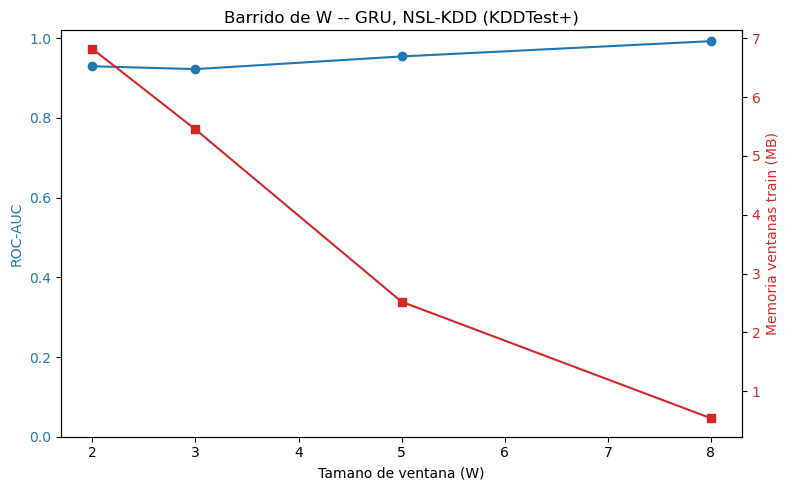

In [7]:
import matplotlib.pyplot as plt

df_plot = df_res.dropna(subset=['roc_auc'])

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.set_xlabel('Tamano de ventana (W)')
ax1.set_ylabel('ROC-AUC', color='tab:blue')
ax1.plot(df_plot['W'], df_plot['roc_auc'], marker='o', color='tab:blue', label='ROC-AUC')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, 1.02)

ax2 = ax1.twinx()
ax2.set_ylabel('Memoria ventanas train (MB)', color='tab:red')
ax2.plot(df_plot['W'], df_plot['memoria_train_MB'], marker='s', color='tab:red', label='Memoria (MB)')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title(TITLE)
fig.tight_layout()
plt.show()

## Resultado

| W | ventanas train | memoria | AUC |
|---|---|---|---|
| 2 | 7165 | 6.8 MB | 0.9298 |
| 3 | 3814 | 5.4 MB | 0.9227 |
| 5 (elegido) | 1059 | 2.5 MB | 0.9545 |
| 8 | 142 | 0.5 MB | 0.9928 |
| 12 | 15 | 0.1 MB | indefinido |

El factor limitante es el número de ventanas formadas solo por tráfico normal, que cae rápidamente al aumentar W. W = 8 da el AUC más alto, pero con solo 142 ventanas de entrenamiento, por lo que se mantiene W = 5.